In [3]:
import pandas as pd
from pathlib import Path

catalog_path = Path("data/combined/prototype_catalog.csv")
df = pd.read_csv(catalog_path)

# Resolve paths and keep only existing crop images
df["crop_path"] = df["crop_path"].apply(
    lambda p: str(Path(p).resolve())
)

existing_paths = {
    str(p.resolve())
    for p in (Path("data/combined/crops")).rglob("*")
    if p.is_file() and p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".webp", ".bmp"
    }
}

df = df[df["crop_path"].isin(existing_paths)].copy()

# Save the synchronized catalog
df.to_csv(catalog_path, index=False)

print("Catalog entries:", len(df))
print("Unique SKUs:", df["sku"].nunique())
print("Missing images:", len(df) - df["crop_path"].isin(existing_paths).sum())
print("\nProducts by category:")
print(df["class_name"].value_counts())

Catalog entries: 10269
Unique SKUs: 10269
Missing images: 0

Products by category:
class_name
Nut        2846
Gear       2718
Bolt       2548
Bearing    2157
Name: count, dtype: int64


In [3]:
import torch
from transformers import AutoImageProcessor, AutoModel

MODEL_NAME = "nateraw/vit-base-beans"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device)
model.eval()

print("Model:", MODEL_NAME)
print("Embedding dimension:", model.config.hidden_size)

Device: cpu


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: nateraw/vit-base-beans
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.bias   | MISSING    | 
pooler.dense.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: nateraw/vit-base-beans
Embedding dimension: 768


In [5]:
import torch
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

In [ ]:
BATCH_SIZE = 32

all_embeddings = []
valid_indices = []

print("Batch size:", BATCH_SIZE)
print("Catalog entries:", len(df))
print("Embedding dimension:", model.config.hidden_size)

Batch size: 32
Catalog entries: 10269
Embedding dimension: 768


Image ID: CROP-000001
Class: Bolt
SKU: BLT-000001
Image path: /home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping/data/combined/crops/bolt/CROP-000001.jpg
Image size: (56, 170)


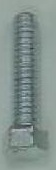

In [7]:
from PIL import Image
from IPython.display import display

sample_row = df.iloc[0]

print("Image ID:", sample_row["crop_id"])
print("Class:", sample_row["class_name"])
print("SKU:", sample_row["sku"])
print("Image path:", sample_row["crop_path"])

sample_image = Image.open(sample_row["crop_path"]).convert("RGB")

print("Image size:", sample_image.size)
display(sample_image)

In [8]:
inputs = processor(images=sample_image, return_tensors="pt")

inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

print("Output shape:", outputs.last_hidden_state.shape)

Output shape: torch.Size([1, 197, 768])


In [9]:
import torch.nn.functional as F

embedding = outputs.last_hidden_state[:, 0, :]

embedding = F.normalize(embedding, p=2, dim=1)

print("Embedding shape:", embedding.shape)
print("First 10 values:", embedding[0, :10].cpu().numpy())
print("Vector magnitude:", embedding.norm(p=2, dim=1).item())

Embedding shape: torch.Size([1, 768])
First 10 values: [-0.08265232 -0.03349252  0.04874386  0.03315994 -0.00335474 -0.06538558
  0.00479814 -0.01437091  0.00857756  0.01854361]
Vector magnitude: 1.0


In [10]:
BATCH_SIZE = 32

all_embeddings = []
valid_indices = []

total_images = len(df)
total_batches = (total_images + BATCH_SIZE - 1) // BATCH_SIZE

print("Total images:", total_images)
print("Batch size:", BATCH_SIZE)
print("Total batches:", total_batches)

Total images: 10269
Batch size: 32
Total batches: 321


In [11]:
for start in tqdm(range(0, len(df), BATCH_SIZE), desc="Generating embeddings"):
    batch_df = df.iloc[start:start + BATCH_SIZE]

    images = []
    batch_indices = []

    for idx, row in batch_df.iterrows():
        try:
            image = Image.open(row["crop_path"]).convert("RGB")
            images.append(image)
            batch_indices.append(idx)
        except Exception as e:
            print(f"Skipping {row['crop_id']}: {e}")

    if not images:
        continue

    inputs = processor(images=images, return_tensors="pt")
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    batch_embeddings = outputs.last_hidden_state[:, 0, :]
    batch_embeddings = F.normalize(batch_embeddings, p=2, dim=1)

    all_embeddings.append(batch_embeddings.cpu().numpy())
    valid_indices.extend(batch_indices)

print("\nEmbedding generation complete!")
print("Images processed:", len(valid_indices))

Generating embeddings: 100%|██████████| 321/321 [16:15<00:00,  3.04s/it]


Embedding generation complete!
Images processed: 10269


In [12]:
embeddings = np.concatenate(all_embeddings, axis=0)

embedded_df = df.loc[valid_indices].copy().reset_index(drop=True)

print("Embeddings shape:", embeddings.shape)
print("Catalog shape:", embedded_df.shape)
print("First embedding norm:", np.linalg.norm(embeddings[0]))
print("\nFirst catalog entry:")
display(embedded_df.head(1))

Embeddings shape: (10269, 768)
Catalog shape: (10269, 18)
First embedding norm: 1.0

First catalog entry:


,crop_id,class_id,class_name,source_image,label_line,x1,y1,x2,y2,crop_width,crop_height,crop_path,product_id,sku,manufacturer,manufacturer_part_number,data_origin,verification_status
0,CROP-000001,1,Bolt,239_jpg.rf.a8e5954b06053030346dd3864d2e63cf.jpg,1,244,180,300,350,56,170,/home/abi/vison-model/Vision-Based Product Att...,NaN,BLT-000001,Apex Industrial,SYN-BLT-000001,synthetic,synthetic


In [13]:
assert len(embeddings) == len(embedded_df), "Embedding/catalog count mismatch!"
assert embeddings.shape[1] == 768, "Unexpected embedding dimension!"
assert embedded_df["crop_path"].notna().all(), "Missing crop paths!"
assert embedded_df["sku"].notna().all(), "Missing SKUs!"

print("All checks passed!")
print("Total embeddings:", len(embeddings))
print("Unique crop IDs:", embedded_df["crop_id"].nunique())
print("Unique SKUs:", embedded_df["sku"].nunique())

All checks passed!
Total embeddings: 10269
Unique crop IDs: 10269
Unique SKUs: 10269


In [19]:
import chromadb
from pathlib import Path

CHROMA_DIR = Path("data") / "chroma_db"

client = chromadb.PersistentClient(path=str(CHROMA_DIR))

collection = client.get_or_create_collection(
    name="mechanical_parts_images",
    metadata={"hnsw:space": "cosine"}
)

print("ChromaDB initialized!")
print("Database path:", CHROMA_DIR)
print("Collection:", collection.name)
print("Existing records:", collection.count())

ChromaDB initialized!
Database path: data/chroma_db
Collection: mechanical_parts_images
Existing records: 0


In [20]:
metadata_columns = [
    "crop_id",
    "class_name",
    "sku",
    "manufacturer",
    "manufacturer_part_number",
    "data_origin",
    "verification_status",
    "crop_path",
]

print("Metadata columns available:")
print(embedded_df[metadata_columns].columns.tolist())

print("\nSample metadata:")
display(embedded_df[metadata_columns].head(3))


Metadata columns available:
['crop_id', 'class_name', 'sku', 'manufacturer', 'manufacturer_part_number', 'data_origin', 'verification_status', 'crop_path']

Sample metadata:


,crop_id,class_name,sku,manufacturer,manufacturer_part_number,data_origin,verification_status,crop_path
0,CROP-000001,Bolt,BLT-000001,Apex Industrial,SYN-BLT-000001,synthetic,synthetic,/home/abi/vison-model/Vision-Based Product Att...
1,CROP-000002,Bolt,BLT-000002,Nova Mechanical,SYN-BLT-000002,synthetic,synthetic,/home/abi/vison-model/Vision-Based Product Att...
2,CROP-000003,Nut,NUT-000001,Titan Components,SYN-NUT-000001,synthetic,synthetic,/home/abi/vison-model/Vision-Based Product Att...


In [21]:
BATCH_SIZE_DB = 500

for start in tqdm(range(0, len(embedded_df), BATCH_SIZE_DB), desc="Storing in ChromaDB"):
    end = min(start + BATCH_SIZE_DB, len(embedded_df))

    batch_df = embedded_df.iloc[start:end]

    collection.add(
        ids=batch_df["crop_id"].tolist(),
        embeddings=embeddings[start:end].tolist(),
        metadatas=batch_df[metadata_columns].to_dict(orient="records"),
    )

print("\nInsertion complete!")
print("Total records in ChromaDB:", collection.count())

Storing in ChromaDB: 100%|██████████| 21/21 [00:06<00:00,  3.30it/s]


Insertion complete!
Total records in ChromaDB: 10269


In [22]:
results = collection.get(
    limit=3,
    include=["metadatas", "embeddings"]
)

print("Records retrieved:", len(results["ids"]))
print("First record ID:", results["ids"][0])
print("First record metadata:", results["metadatas"][0])
print("First embedding dimension:", len(results["embeddings"][0]))

Records retrieved: 3
First record ID: CROP-000001
First record metadata: {'manufacturer': 'Apex Industrial', 'crop_path': '/home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping/data/combined/crops/bolt/CROP-000001.jpg', 'data_origin': 'synthetic', 'sku': 'BLT-000001', 'class_name': 'Bolt', 'crop_id': 'CROP-000001', 'manufacturer_part_number': 'SYN-BLT-000001', 'verification_status': 'synthetic'}
First embedding dimension: 768


In [13]:
from pathlib import Path
from ultralytics import YOLO

YOLO_MODEL_PATH = Path.cwd() / "models" / "machine_parts_best.pt"

yolo_model = YOLO(YOLO_MODEL_PATH)

print("YOLO model loaded successfully!")
print("Classes:", yolo_model.names)

YOLO model loaded successfully!
Classes: {0: 'Bearing', 1: 'Bolt', 2: 'Gear', 3: 'Nut'}


Image loaded successfully!
Image size: (640, 640)
Detected objects: 1


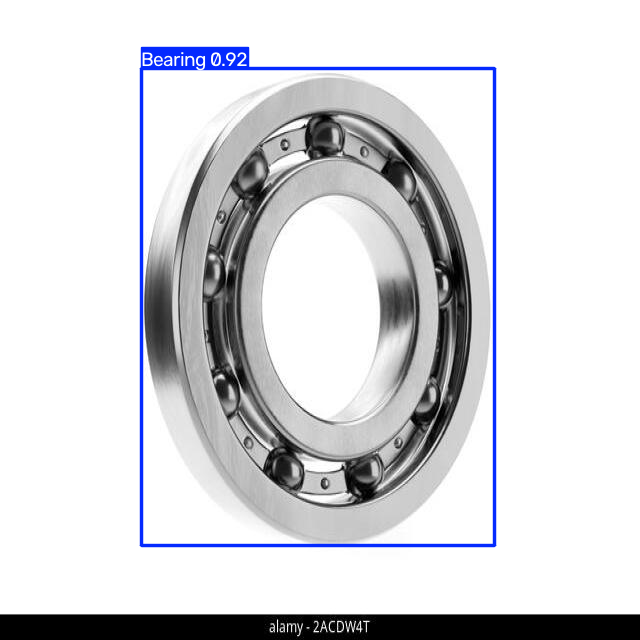

In [15]:
from pathlib import Path
from PIL import Image
from IPython.display import display
from ultralytics import YOLO

QUERY_IMAGE_PATH = "/home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping/data/test/images/2acdw4t_jpg.rf.217ed4256b6f0420926115b1b80e97d7.jpg"
QUERY_IMAGE_PATH = Path(QUERY_IMAGE_PATH).expanduser()

if not QUERY_IMAGE_PATH.is_file():
    print("Image not found. Please check the path.")
else:
    query_image = Image.open(QUERY_IMAGE_PATH).convert("RGB")
    print("Image loaded successfully!")
    print("Image size:", query_image.size)

    # Run YOLO detection
    yolo_results = yolo_model.predict(
        source=query_image,
        conf=0.25,
        iou=0.45,
        verbose=False
    )

    # Draw bounding boxes and class labels
    bounded_image = yolo_results[0].plot()
    bounded_image = Image.fromarray(bounded_image[:, :, ::-1])

    print("Detected objects:", len(yolo_results[0].boxes))
    display(bounded_image)


In [4]:
import torch
from transformers import AutoImageProcessor, AutoModel

MODEL_NAME = "nateraw/vit-base-beans"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device)
model.eval()

print("Model:", MODEL_NAME)
print("Embedding dimension:", model.config.hidden_size)

Device: cpu


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: nateraw/vit-base-beans
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.bias   | MISSING    | 
pooler.dense.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: nateraw/vit-base-beans
Embedding dimension: 768


In [7]:
import torch.nn.functional as F
import numpy as np
inputs = processor(images=query_image, return_tensors="pt")
inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

query_embedding = outputs.last_hidden_state[:, 0, :]
query_embedding = F.normalize(query_embedding, p=2, dim=1)

query_embedding = query_embedding[0].cpu().numpy()

print("Query embedding shape:", query_embedding.shape)
print("Embedding norm:", np.linalg.norm(query_embedding))

Query embedding shape: (768,)
Embedding norm: 0.99999994


In [9]:
import chromadb
from pathlib import Path

CHROMA_DIR = Path("data") / "chroma_db"

client = chromadb.PersistentClient(path=str(CHROMA_DIR))

collection = client.get_or_create_collection(
    name="mechanical_parts_images",
    metadata={"hnsw:space": "cosine"}
)

print("ChromaDB initialized!")
print("Database path:", CHROMA_DIR)
print("Collection:", collection.name)
print("Existing records:", collection.count())

ChromaDB initialized!
Database path: data/chroma_db
Collection: mechanical_parts_images
Existing records: 10269


In [10]:
search_results = collection.query(
    query_embeddings=[query_embedding.tolist()],
    n_results=5,
    include=["metadatas", "distances"]
)

for i, (metadata, distance) in enumerate(
    zip(
        search_results["metadatas"][0],
        search_results["distances"][0]
    ),
    start=1
):
    similarity = 1 - distance

    print(f"\n--- Match {i} ---")
    print("Class:", metadata["class_name"])
    print("SKU:", metadata["sku"])
    print("Manufacturer:", metadata["manufacturer"])
    print("Part number:", metadata["manufacturer_part_number"])
    print("Crop ID:", metadata["crop_id"])
    print(f"Cosine similarity: {similarity:.4f}")


--- Match 1 ---
Class: Bearing
SKU: BRG-000034
Manufacturer: Nova Mechanical
Part number: SYN-BRG-000034
Crop ID: CROP-000410
Cosine similarity: 0.9920

--- Match 2 ---
Class: Bearing
SKU: BRG-000037
Manufacturer: Apex Industrial
Part number: SYN-BRG-000037
Crop ID: CROP-000413
Cosine similarity: 0.9704

--- Match 3 ---
Class: Bearing
SKU: BRG-000073
Manufacturer: Titan Components
Part number: SYN-BRG-000073
Crop ID: CROP-000663
Cosine similarity: 0.9697

--- Match 4 ---
Class: Bearing
SKU: BRG-000009
Manufacturer: Vertex Engineering
Part number: SYN-BRG-000009
Crop ID: CROP-000368
Cosine similarity: 0.9693

--- Match 5 ---
Class: Bearing
SKU: BRG-000036
Manufacturer: Vertex Engineering
Part number: SYN-BRG-000036
Crop ID: CROP-000412
Cosine similarity: 0.9611


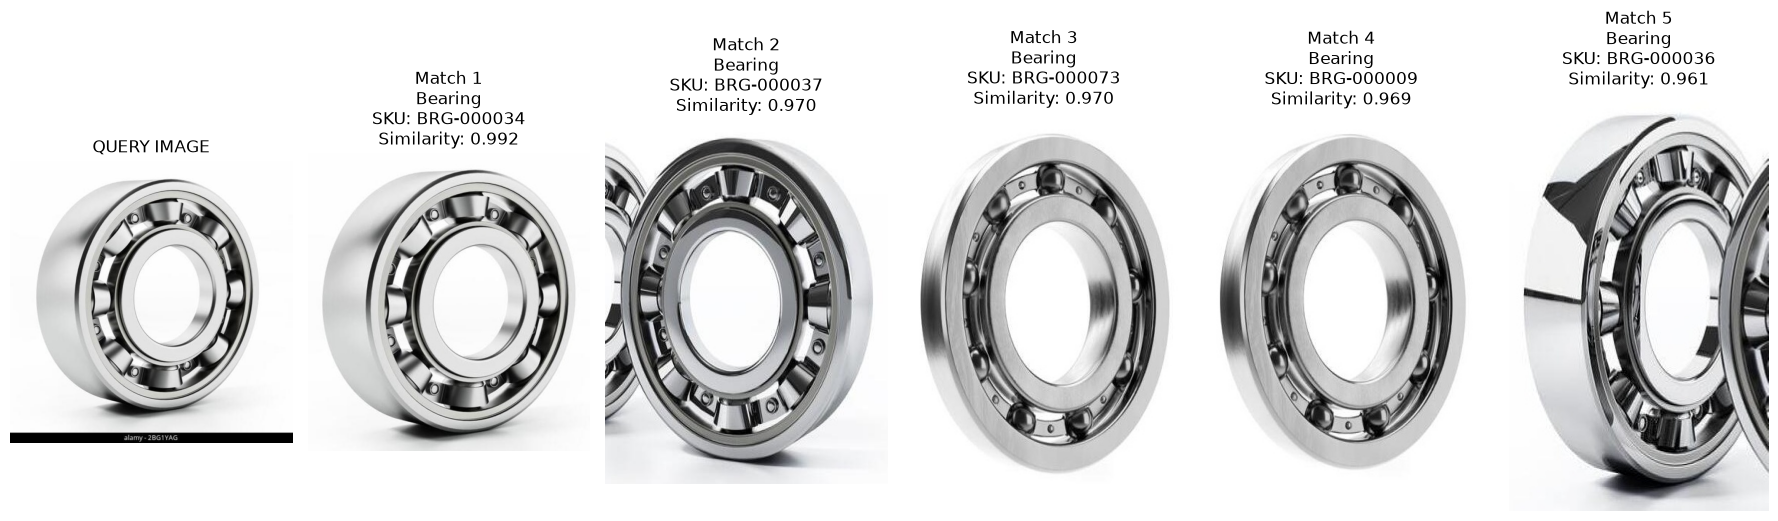

In [11]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 6, figsize=(18, 5))

# Display the query image
axes[0].imshow(query_image)
axes[0].set_title("QUERY IMAGE")
axes[0].axis("off")

# Display the five retrieved matches
for i, metadata in enumerate(search_results["metadatas"][0]):
    matched_image = Image.open(metadata["crop_path"]).convert("RGB")

    similarity = 1 - search_results["distances"][0][i]

    axes[i + 1].imshow(matched_image)
    axes[i + 1].set_title(
        f"Match {i + 1}\n"
        f"{metadata['class_name']}\n"
        f"SKU: {metadata['sku']}\n"
        f"Similarity: {similarity:.3f}"
    )
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()